<a href="https://colab.research.google.com/github/OscarGalloGarcia/Msc-DeepLearning-course/blob/main/L05_Red_Neuronal_Densa_TF_Housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Neuronal Densa en TensorFlow
## Dr. Carlos Villaseñor


### Alumno: Oscar Alberto Gallo García
Msc Ciencias en Robótica e Inteligencia Artificial


A05 Redes Densas con TensorFlow

Dataset: "BreastCancerWisconsin.csv" cuya variable de interés es "diagnosis"

Paso 1. Correr paqueterias

In [2]:
# Paquetería básica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importamos Tensorflow y Keras
import tensorflow as tf
from tensorflow import keras

# Usamos funcionalidades básicas de Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
# tensor flow version y ver si detecta la GPU de colab
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))
print(tf.config.experimental.get_device_details(tf.config.list_physical_devices('GPU')[0]))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{'compute_capability': (7, 5), 'device_name': 'Tesla T4'}


Paso 2. Carga el archivo, y la lectura con pandas

In [4]:
!wget 'https://github.com/Dr-Carlos-Villasenor/Clase_Aprendizaje_Profundo/raw/main/Datasets/Housing.csv'

--2026-10-12 03:16:17--  https://github.com/Dr-Carlos-Villasenor/Clase_Aprendizaje_Profundo/raw/main/Datasets/Housing.csv
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Dr-Carlos-Villasenor/Clase_Aprendizaje_Profundo/main/Datasets/Housing.csv [following]
--2026-10-12 03:16:18--  https://raw.githubusercontent.com/Dr-Carlos-Villasenor/Clase_Aprendizaje_Profundo/main/Datasets/Housing.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 29981 (29K) [text/plain]
Saving to: ‘Housing.csv’

Housing.csv         100%[===================>]  29.28K  --.-KB/s    in 0.003s  

2026-10-12 03:16:18 (9.17 MB/s) -

In [5]:
dataset = pd.read_csv('Housing.csv')
dataset.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Paso 3. Limpieza de los datos

In [6]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [5]:
# Como tenemos varias columnas con texto debemos aplicar One-hot encoding
origin = dataset.pop('furnishingstatus')
dataset['furnished'] = (origin == 1)*1.0
dataset['semi-furnished'] = (origin == 2)*1.0
dataset[''] = (origin == 3)*1.0
dataset.tail()


dataset.head()

KeyError: 'diagnosis'

In [8]:
np.array(dataset.price)

array([13300000, 12250000, 12250000, 12215000, 11410000, 10850000,
       10150000, 10150000,  9870000,  9800000,  9800000,  9681000,
        9310000,  9240000,  9240000,  9100000,  9100000,  8960000,
        8890000,  8855000,  8750000,  8680000,  8645000,  8645000,
        8575000,  8540000,  8463000,  8400000,  8400000,  8400000,
        8400000,  8400000,  8295000,  8190000,  8120000,  8080940,
        8043000,  7980000,  7962500,  7910000,  7875000,  7840000,
        7700000,  7700000,  7560000,  7560000,  7525000,  7490000,
        7455000,  7420000,  7420000,  7420000,  7350000,  7350000,
        7350000,  7350000,  7343000,  7245000,  7210000,  7210000,
        7140000,  7070000,  7070000,  7035000,  7000000,  6930000,
        6930000,  6895000,  6860000,  6790000,  6790000,  6755000,
        6720000,  6685000,  6650000,  6650000,  6650000,  6650000,
        6650000,  6650000,  6629000,  6615000,  6615000,  6580000,
        6510000,  6510000,  6510000,  6475000,  6475000,  6440

Paso 3. Revisar datos faltantes

In [9]:
dataset.isna().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


Paso 7. Elige las variables de entrada y salida

In [10]:
x = np.asanyarray(dataset.drop(columns=['price']))
y = np.asanyarray(dataset[['price']])
x = StandardScaler().fit_transform(x)
print(x.shape)
print(y.shape)

ValueError: could not convert string to float: 'yes'

Paso 8. Particiona el dataset

In [ ]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2)

Paso 9. Crea una red neuronal para aprender los datos.

In [ ]:
from keras import ops
from keras import backend as K



In [ ]:
def build_model():

  model = keras.Sequential()
  model.add(keras.layers.Dense(128, activation='relu', input_shape=[x.shape[1]]))
  model.add(keras.layers.Dropout(0.5))
  model.add(keras.layers.Dense(32, activation='tanh'))
  #Capa de salida con la funcion logistica -> sigmoid
  #Se pone esto en la salida porque es un problema de clasificacion
  model.add(keras.layers.Dense(1, activation='sigmoid'))

  #En la funcion de costo se usa BCE
  # En metricas en lugar de r2score se usa accuracy
  model.compile(loss='binary_crossentropy',
                optimizer=keras.optimizers.Adam(),
                metrics=['accuracy'])
  return  model

In [ ]:
model = build_model()
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,129 (31.75 KB)

 Trainable params: 8,129 (31.75 KB)

 Non-trainable params: 0 (0.00 B)

Paso 10. Entrena la red neuronal

In [ ]:
history = model.fit(xtrain, ytrain,
                    batch_size=150, epochs=3000,
                    validation_data=(xtest, ytest), verbose=0)

KeyboardInterrupt: 

Paso 11. Dibuja las curvas de aprendizaje para un mejor diagnóstico del aprendizaje

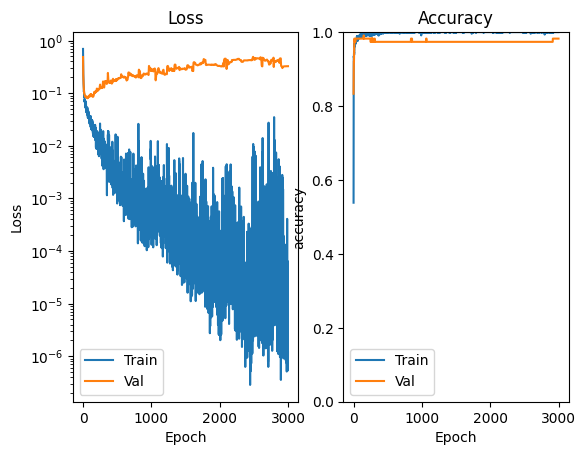

In [ ]:
def plot_history(history):
  hist = pd.DataFrame(history.history)
  hist['epoch'] = history.epoch
  plt.figure()
  plt.subplot(121)
  plt.title('Loss')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.plot(hist['epoch'], hist['loss'],
           label='Train')
  plt.plot(hist['epoch'], hist['val_loss'],
           label = 'Val')
  plt.yscale('log')
  plt.legend()

  plt.subplot(122)
  plt.title('Accuracy')
  plt.xlabel('Epoch')
  plt.ylabel('accuracy')
  plt.plot(hist['epoch'], hist['accuracy'],
           label='Train')
  plt.plot(hist['epoch'], hist['val_accuracy'],
           label = 'Val')
  plt.ylim([0,1])
  plt.legend()

plot_history(history)

Paso 12. Implementación de Eary Stopping como regulador

Epoch 1/3000


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 300ms/step - accuracy: 0.7473 - loss: 0.5532 - val_accuracy: 0.9474 - val_loss: 0.3626
Epoch 2/3000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8813 - loss: 0.3969 - val_accuracy: 0.9561 - val_loss: 0.2748
Epoch 3/3000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9319 - loss: 0.2839 - val_accuracy: 0.9561 - val_loss: 0.2254
Epoch 4/3000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9429 - loss: 0.2252 - val_accuracy: 0.9561 - val_loss: 0.1962
Epoch 5/3000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9429 - loss: 0.2005 - val_accuracy: 0.9561 - val_loss: 0.1775
Epoch 6/3000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9429 - loss: 0.1728 - val_accuracy: 0.9649 - val_loss: 0.1640
Epoch 7/3000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9407 - loss: 0.1625 - val_accuracy: 0.9649 - val_loss: 0.1526
Epoch 8/3000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9516 - loss: 0.1426 - val_accuracy: 0.9649 - val_loss: 0.1

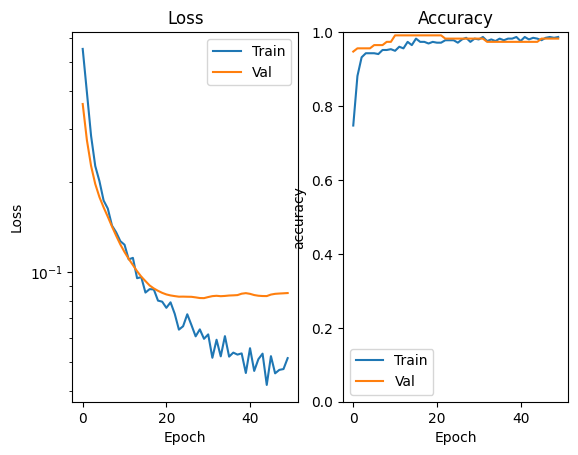

In [ ]:
es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=20)
model = build_model()
history = model.fit(xtrain, ytrain,
                    batch_size=150, epochs=3000,
                    validation_data=(xtest, ytest),
                    verbose=1, callbacks=[es])

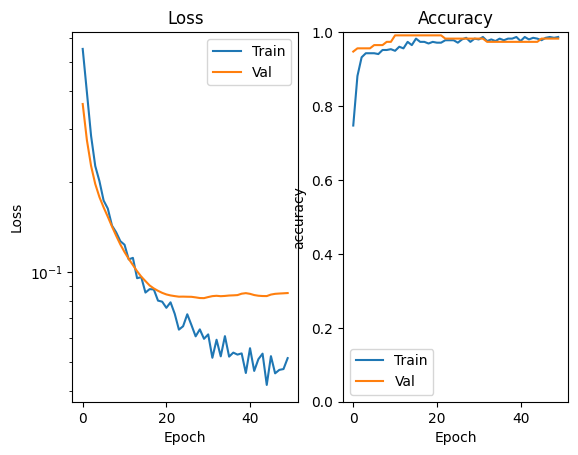

In [ ]:
plot_history(history)

In [ ]:
# Descargar en HTML con el nombre exacto detectado en tu sesión
!jupyter nbconvert --to html "L05_Red_Neuronal_Densa_TF_BreastCancerWisconsin (1).ipynb"

[NbConvertApp] Converting notebook L05_Red_Neuronal_Densa_TF_BreastCancerWisconsin (1).ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 1045981 bytes to L05_Red_Neuronal_Densa_TF_BreastCancerWisconsin (1).html
